In [4]:
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

In [5]:
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"

order_features = pd.read_csv(
    processed_dir / "order_features.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

customer_summary = pd.read_csv(
    processed_dir / "customer_summary.csv"
)

seller_summary = pd.read_csv(
    processed_dir / "seller_summary.csv"
)

print("Order features:", order_features.shape)
print("Customer summary:", customer_summary.shape)
print("Seller summary:", seller_summary.shape)

Order features: (99441, 11)
Customer summary: (93358, 4)
Seller summary: (3095, 6)


In [6]:
order_features[
    [
        "total_order_value",
        "delivery_days"
    ]
].describe()

,total_order_value,delivery_days
count,99441.000000,96476.000000
mean,159.326166,12.094086
std,220.058804,9.551746
min,0.000000,0.000000
25%,61.050000,6.000000
50%,104.560000,10.000000
75%,176.000000,15.000000
max,13664.080000,209.000000


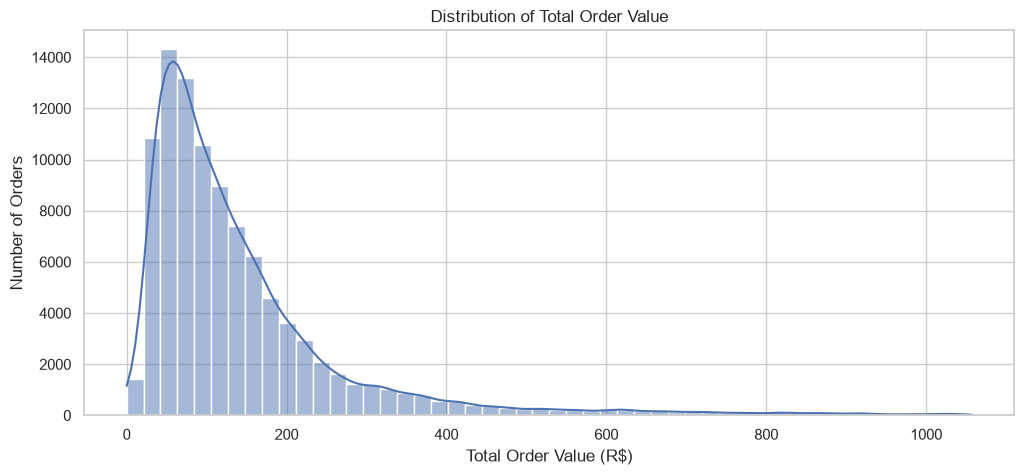

In [16]:
upper_limit = order_features[
    "total_order_value"
].quantile(0.99)

order_value_plot = order_features[
    order_features["total_order_value"] <= upper_limit
].copy()

plt.figure(figsize=(12, 5))

sns.histplot(
    data=order_value_plot,
    x="total_order_value",
    bins=50,
    kde=True
)

plt.title("Distribution of Total Order Value")
plt.xlabel("Total Order Value (R$)")
plt.ylabel("Number of Orders")

plt.show()

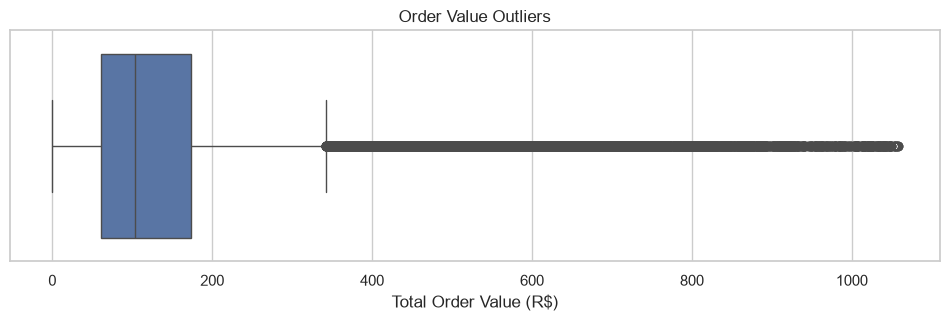

In [17]:
plt.figure(figsize=(12,3))

sns.boxplot(
    data=order_value_plot,
    x="total_order_value"
)

plt.title("Order Value Outliers")
plt.xlabel("Total Order Value (R$)")

plt.show()

In [18]:
## Bivariate Analysis: Delivery Performance and Review Scores

In [19]:
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

mysql_username = input("MySQL username [root]: ").strip() or "root"
mysql_password = getpass("MySQL password: ")

connection_url = URL.create(
    drivername="mysql+pymysql",
    username=mysql_username,
    password=mysql_password,
    host="localhost",
    port=3306,
    database="cart2insights"
)

engine = create_engine(connection_url, pool_pre_ping=True)

reviews = pd.read_sql(
    "SELECT order_id, review_score FROM reviews",
    engine
)

review_by_order = (
    reviews.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

eda_orders = order_features.merge(
    review_by_order,
    on="order_id",
    how="left"
)

delivery_plot = eda_orders[
    eda_orders["delivery_status"].isin(["On Time", "Delayed"])
].copy()

delivery_plot.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,total_order_value,delivery_days,delivery_status,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,72.19,7.0,On Time,5.0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,259.83,16.0,On Time,4.0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,216.87,7.0,On Time,5.0
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,25.78,6.0,On Time,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,218.04,25.0,On Time,5.0


,delivery_status,average_review_score,reviewed_orders
0,Delayed,2.566506,7661
1,On Time,4.294292,88163


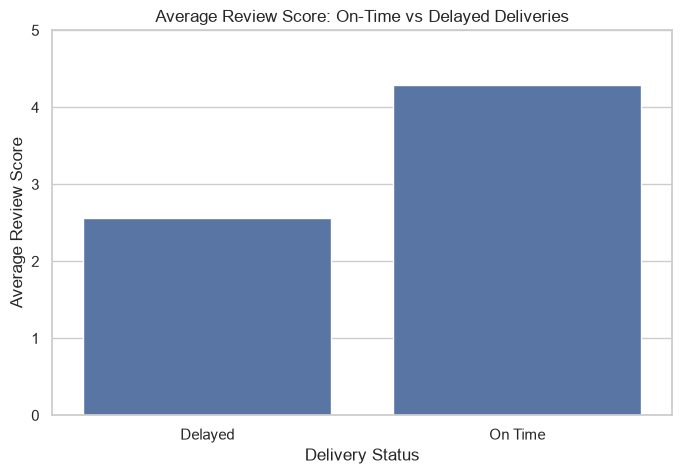

In [20]:
review_summary = (
    delivery_plot.groupby("delivery_status", as_index=False)
    .agg(
        average_review_score=("review_score", "mean"),
        reviewed_orders=("review_score", "count")
    )
)

display(review_summary)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=review_summary,
    x="delivery_status",
    y="average_review_score"
)

plt.title("Average Review Score: On-Time vs Delayed Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)

plt.show()

In [22]:
# Insight

#On-time deliveries received an average review score of 4.29, while delayed deliveries received only 2.57. This shows a strong negative relationship between delivery delays and customer satisfaction. Improving delivery reliability should be a key business priority.

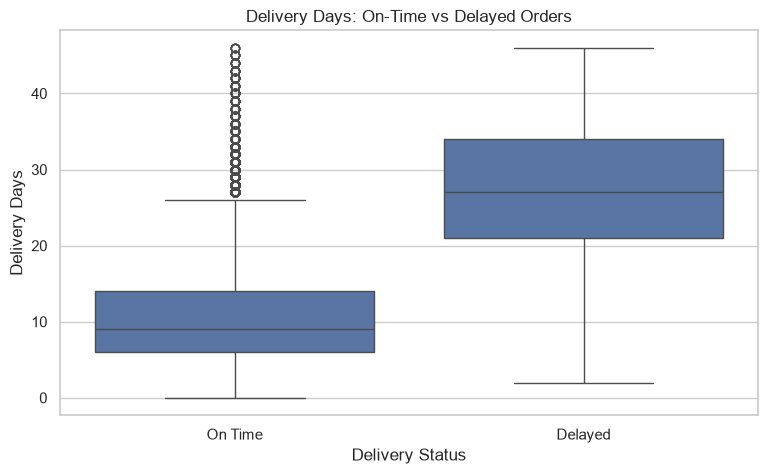

In [23]:
delivery_days_plot = delivery_plot[
    delivery_plot["delivery_days"].between(
        0,
        delivery_plot["delivery_days"].quantile(0.99)
    )
].copy()

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=delivery_days_plot,
    x="delivery_status",
    y="delivery_days"
)

plt.title("Delivery Days: On-Time vs Delayed Orders")
plt.xlabel("Delivery Status")
plt.ylabel("Delivery Days")

plt.show()

In [27]:
# Insight
#Delayed orders had a much higher median delivery time than on-time orders. 
# Some on-time orders also took many days to arrive, 
# showing that delivery status depends on whether the promised delivery date was met, 
# not only on the number of delivery days.

,total_order_value,delivery_days,review_score
total_order_value,1.000000,0.069291,-0.042076
delivery_days,0.069291,1.000000,-0.334150
review_score,-0.042076,-0.334150,1.000000


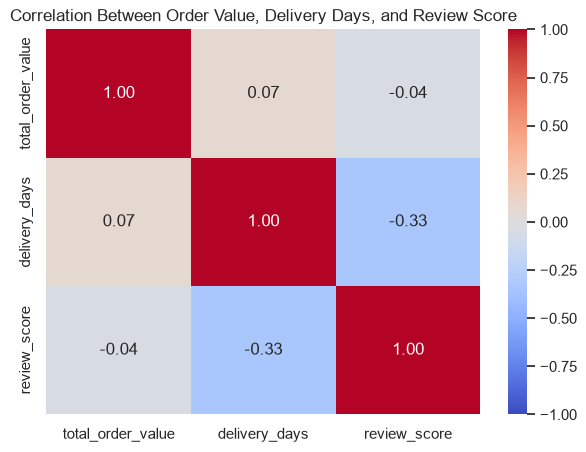

In [25]:
correlation_data = eda_orders[
    ["total_order_value", "delivery_days", "review_score"]
].dropna()

correlation_matrix = correlation_data.corr()

display(correlation_matrix)

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Order Value, Delivery Days, and Review Score")
plt.show()

In [28]:
# Insight
#Delivery days and review score have a moderate negative correlation of -0.33, meaning longer delivery times are generally associated with lower customer satisfaction. Order value has almost no correlation with either delivery time or review score. Therefore, improving logistics is likely to have a greater customer-experience impact than focusing only on order value.

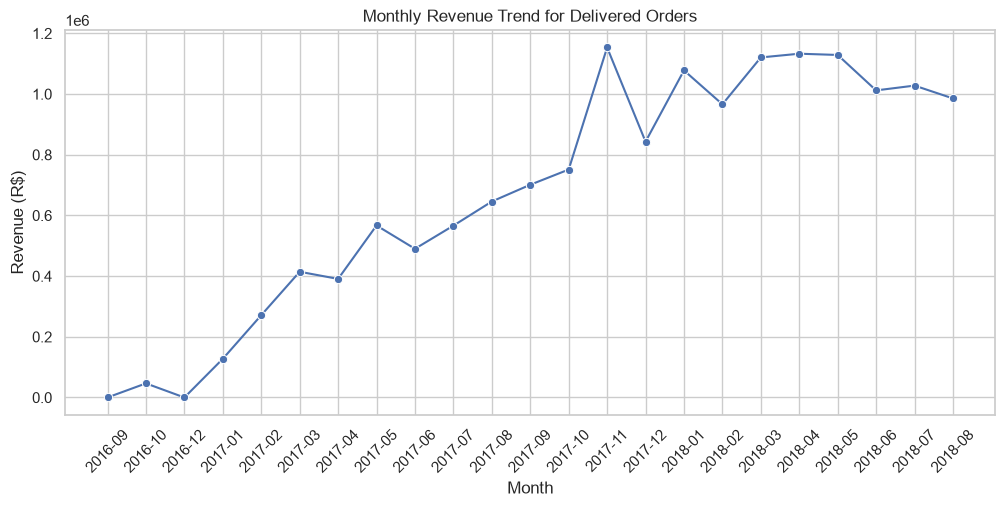

In [29]:
order_features["order_purchase_timestamp"] = pd.to_datetime(
    order_features["order_purchase_timestamp"]
)

monthly_revenue = (
    order_features[
        order_features["order_status"] == "delivered"
    ]
    .assign(
        month=lambda df: df["order_purchase_timestamp"].dt.to_period("M").astype(str)
    )
    .groupby("month", as_index=False)["total_order_value"]
    .sum()
    .rename(columns={"total_order_value": "revenue"})
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_revenue,
    x="month",
    y="revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend for Delivered Orders")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)

plt.show()

In [31]:
# Category Performance Analysis

In [32]:
category_revenue = pd.read_sql(
    """
    SELECT
        COALESCE(p.product_category_name, 'unknown') AS product_category,
        ROUND(SUM(oi.price + oi.freight_value), 2) AS revenue
    FROM orders AS o
    JOIN order_items AS oi
        ON o.order_id = oi.order_id
    JOIN products AS p
        ON oi.product_id = p.product_id
    WHERE o.order_status = 'delivered'
    GROUP BY p.product_category_name
    ORDER BY revenue DESC
    LIMIT 10;
    """,
    engine
)

display(category_revenue)

,product_category,revenue
0,beleza_saude,1412089.53
1,relogios_presentes,1264333.12
2,cama_mesa_banho,1225209.26
3,esporte_lazer,1118256.91
4,informatica_acessorios,1032723.77
5,moveis_decoracao,880329.92
6,utilidades_domesticas,758392.25
7,cool_stuff,691680.89
8,automotivo,669454.75
9,ferramentas_jardim,567145.68


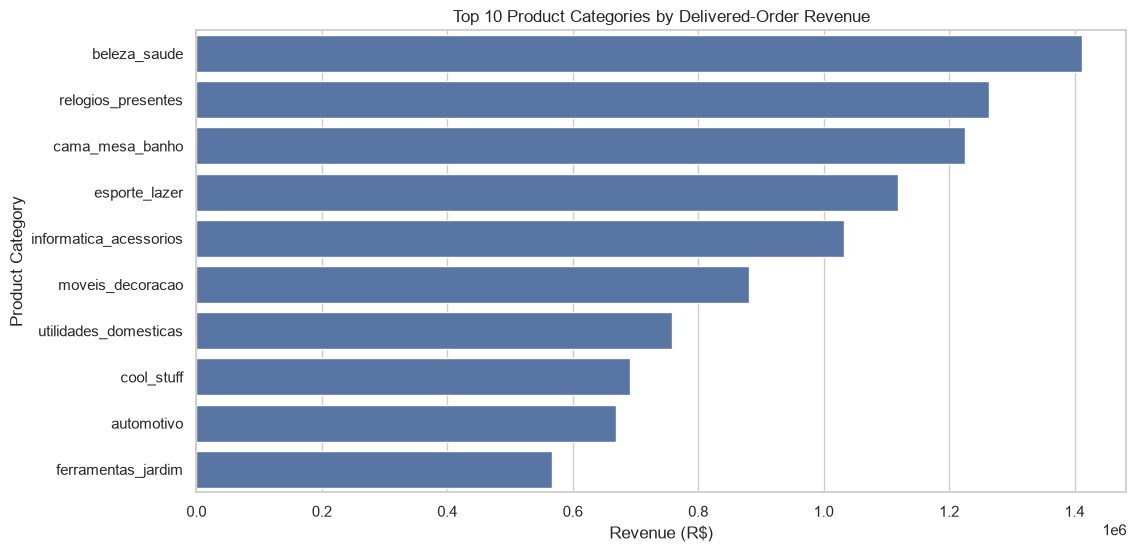

In [33]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_revenue,
    x="revenue",
    y="product_category"
)

plt.title("Top 10 Product Categories by Delivered-Order Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Product Category")

plt.show()

In [34]:
# Customer Retention Analysis

In [35]:
customer_type_counts = (
    customer_summary["repeat_customer"]
    .value_counts()
    .rename_axis("customer_type")
    .reset_index(name="customer_count")
)

customer_type_counts["percentage"] = (
    customer_type_counts["customer_count"]
    / customer_type_counts["customer_count"].sum()
    * 100
).round(2)

display(customer_type_counts)

,customer_type,customer_count,percentage
0,No,90557,97.0
1,Yes,2801,3.0


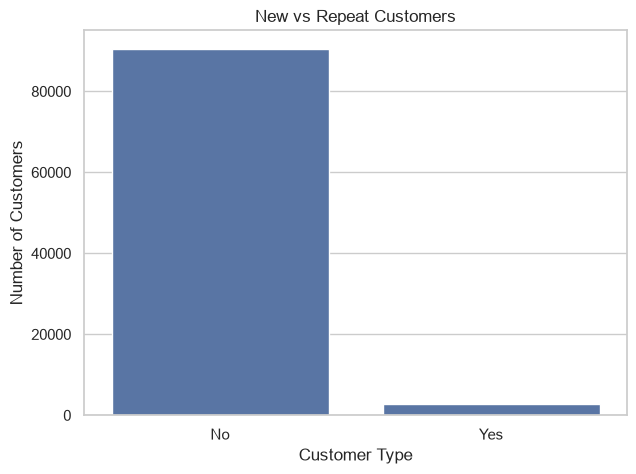

In [36]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=customer_type_counts,
    x="customer_type",
    y="customer_count"
)

plt.title("New vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.show()

In [37]:
top_category = category_revenue.iloc[0]

peak_month = monthly_revenue.loc[
    monthly_revenue["revenue"].idxmax()
]

repeat_customer_row = customer_type_counts[
    customer_type_counts["customer_type"] == "Yes"
]

print("KEY EDA FINDINGS")
print("-" * 50)

print(
    f"Top category: {top_category['product_category']} "
    f"(R$ {top_category['revenue']:,.2f})"
)

print(
    f"Peak revenue month: {peak_month['month']} "
    f"(R$ {peak_month['revenue']:,.2f})"
)

if not repeat_customer_row.empty:
    print(
        f"Repeat-customer percentage: "
        f"{repeat_customer_row.iloc[0]['percentage']:.2f}%"
    )

print("Average delayed-delivery review score: 2.57")
print("Average on-time delivery review score: 4.29")
print("Delivery days vs review correlation: -0.33")

KEY EDA FINDINGS
--------------------------------------------------
Top category: beleza_saude (R$ 1,412,089.53)
Peak revenue month: 2017-11 (R$ 1,153,364.20)
Repeat-customer percentage: 3.00%
Average delayed-delivery review score: 2.57
Average on-time delivery review score: 4.29
Delivery days vs review correlation: -0.33
